# Bank Marketing: Who Is More Likely to Subscribe?

This project looks at a bank's telephone marketing campaign and tries to answer a practical question:

**Can the bank use the information it already has to identify customers who are more likely to subscribe to a term deposit?**

I am using the `bank-additional-full.csv` version of the UCI Bank Marketing dataset. I chose this version because it includes customer information, campaign history, and five economic indicators.

The target variable is `y`:

- `yes` = the customer subscribed
- `no` = the customer did not subscribe

One important point from the dataset documentation is that `duration` is only known after a call has happened. I will use it during exploration, but I will leave it out of the prediction model because the bank would not know the call duration before deciding who to contact.

**Dataset reference:** Moro, S., Cortez, P. & Rita, P. (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. Decision Support Systems.

## 1. Load the data

I start by loading the full dataset and checking the first few rows. I also make the file path a little flexible so the notebook still runs if the downloaded file has `(1)` in its name.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_path = Path("bank-additional-full.csv")

if not data_path.exists():
    data_path = Path("bank-additional-full(1).csv")

df = pd.read_csv(data_path, sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. First look at the dataset

Before cleaning anything, I want to know the size of the data, the column types, and whether Pandas can see any normal missing values.

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (41188, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.id

The full file has **41,188 rows and 21 columns**, which matches the dataset documentation.

Pandas does not show any `NaN` values. That does not mean every field is complete, though. Some categorical columns use the word `unknown`, so I will check those separately.

## 3. Data quality checks

### 3.1 Duplicate rows

I check exact duplicates first. If the same full row appears more than once, keeping every copy could give those records extra influence.

In [3]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 12


In [4]:
df[df.duplicated(keep=False)]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


There are **12 duplicate copies**. The matching rows are identical across all available columns, so I remove the extra copies.

The dataset does not contain a customer ID, so I cannot prove that two identical rows belong to the same person. For this project, treating exact full-row matches as duplicates is a reasonable cleaning decision.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Shape after removing duplicates: (41176, 21)
Duplicates remaining: 0


### 3.2 `unknown` values

Some categorical fields use `unknown` instead of a normal missing value. I want to see where that happens before deciding what to do with it.

In [6]:
categorical_columns = df.select_dtypes(include="object").columns

unknown_summary = []

for column in categorical_columns:
    count = (df[column] == "unknown").sum()
    if count > 0:
        unknown_summary.append({
            "column": column,
            "unknown_count": count,
            "unknown_percent": count / len(df) * 100
        })

unknown_summary = pd.DataFrame(unknown_summary)
unknown_summary.round(2)

,column,unknown_count,unknown_percent
0,job,330,0.80
1,marital,80,0.19
2,education,1730,4.20
3,default,8596,20.88
4,housing,990,2.40
5,loan,990,2.40


The main issue is `default`, where roughly one-fifth of the values are `unknown`. Deleting every row with an `unknown` value would throw away a lot of data, so I will keep `unknown` as its own category.

That choice is simple and transparent. A future version of the project could test whether imputation improves performance.

### 3.3 Numerical summary

I also check the numerical columns for unusual ranges before making any changes.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


A few values need context:

- `pdays = 999` means the customer had **not** been contacted in a previous campaign.
- `duration` can be very large, but I will not remove long calls just because they look unusual.
- `campaign` reaches 56 contacts for a small number of customers. I will look at the pattern before deciding whether that matters.

I am avoiding automatic outlier removal here because an extreme value is not automatically a bad value.

## 4. Target variable

The project is a binary classification problem, so I first check how many customers subscribed.

In [8]:
target_counts = df["y"].value_counts()
target_percent = df["y"].value_counts(normalize=True).mul(100)

print(target_counts)
print()
print(target_percent.round(2))

y
no     36537
yes     4639
Name: count, dtype: int64

y
no     88.73
yes    11.27
Name: proportion, dtype: float64


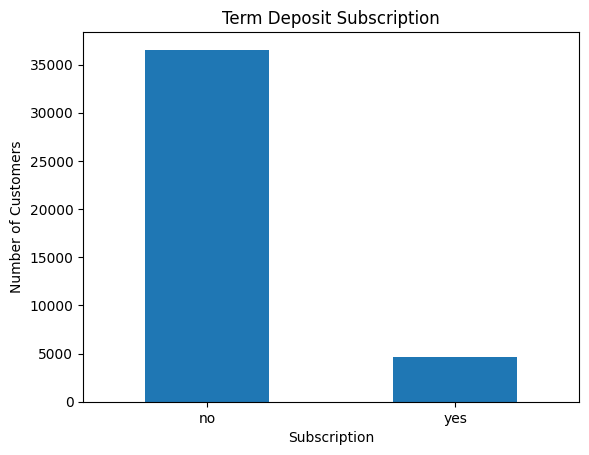

In [9]:
df["y"].value_counts().plot(kind="bar")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

Only about **11.3%** of customers subscribed, while almost **89%** did not.

This matters a lot for modelling. A model could predict `no` most of the time and still get high accuracy, so I will pay attention to recall, precision, F1-score, ROC-AUC, and PR-AUC instead of relying on accuracy alone.

## 5. Exploratory data analysis

I do not need to analyse every column just because it exists. I will focus on variables that help answer the business question or that need special treatment before modelling.

### 5.1 Customer age

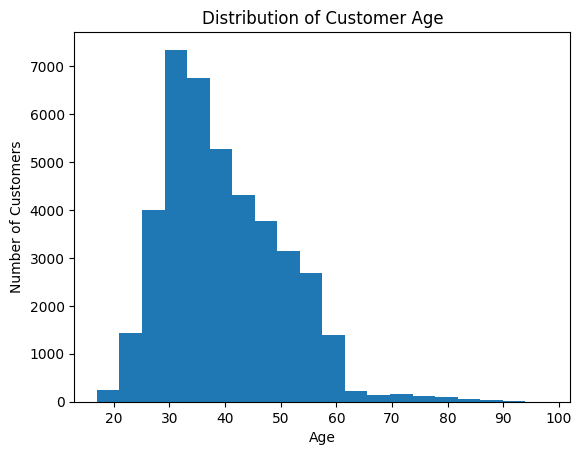

In [10]:
plt.hist(df["age"], bins=20)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

In [11]:
df.groupby("y")["age"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36537.0,39.91,9.90,17.0,32.0,38.0,47.0,95.0
yes,4639.0,40.91,13.84,17.0,31.0,37.0,50.0,98.0


Most customers are between their mid-20s and mid-50s, with the biggest concentration around the 30s.

Subscribers and non-subscribers are fairly similar in age. Their average ages differ by only about one year, so age alone does not look like a strong separator. Subscribers do have a wider spread of ages, especially among older customers.

### 5.2 Job and subscription

In [12]:
job_counts = df["job"].value_counts()

job_subscription_rate = (
    df.groupby("job")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

job_summary = pd.DataFrame({
    "customers": job_counts,
    "subscription_rate_%": job_subscription_rate
}).sort_values("subscription_rate_%", ascending=False)

job_summary.round(2)

,customers,subscription_rate_%
job,,
student,875,31.43
retired,1718,25.26
unemployed,1014,14.20
admin.,10419,12.97
management,2924,11.22
unknown,330,11.21
technician,6739,10.83
self-employed,1421,10.49
housemaid,1060,10.00


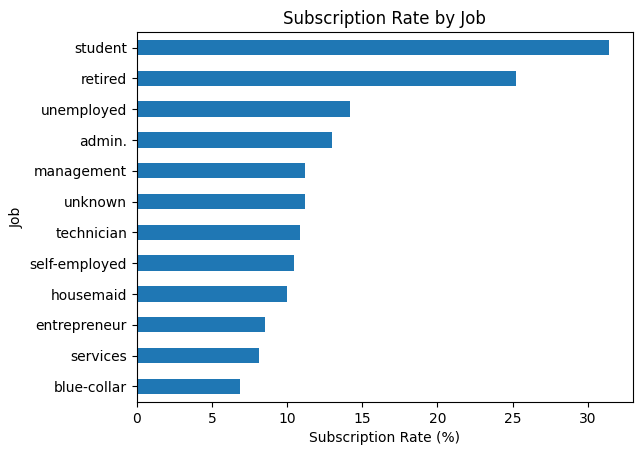

In [13]:
job_subscription_rate.sort_values().plot(kind="barh")

plt.title("Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.show()

Students have the highest subscription rate at about **31%**, followed by retired customers at about **25%**. Blue-collar customers are at the bottom at roughly **7%**.

The group sizes are very different, so I would not use these percentages alone to decide who the bank should target. Job looks useful, but it needs to be considered together with the other variables.

### 5.3 Previous campaign outcome

In [14]:
poutcome_rate = (
    df.groupby("poutcome")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

poutcome_rate.round(2)

poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64

This is one of the clearest patterns in the data.

About **65%** of customers whose previous campaign was successful subscribed in the current campaign. The rate is much lower after a previous failure and lower again when there was no previous campaign outcome.

Previous campaign history looks important for prediction.

### 5.4 Number of contacts in the current campaign

In [15]:
df.groupby("y")["campaign"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36537.0,2.63,2.87,1.0,1.0,2.0,3.0,56.0
yes,4639.0,2.05,1.67,1.0,1.0,2.0,2.0,23.0


In [16]:
df["campaign_group"] = "5+"
df.loc[df["campaign"] == 1, "campaign_group"] = "1"
df.loc[df["campaign"] == 2, "campaign_group"] = "2"
df.loc[df["campaign"] == 3, "campaign_group"] = "3"
df.loc[df["campaign"] == 4, "campaign_group"] = "4"

campaign_rate = (
    df.groupby("campaign_group")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .reindex(["1", "2", "3", "4", "5+"])
)

campaign_rate.round(2)

campaign_group
1     13.04
2     11.46
3     10.75
4      9.40
5+     6.14
Name: y, dtype: float64

The pattern is quite clear: the subscription rate falls as the number of contacts increases.

Customers contacted once converted at about **13%**, while the rate falls to about **6%** for customers contacted five or more times.

I would read this as a sign that repeated calls may have limited value. It does not prove that extra calls make customers less interested; harder-to-convert customers may simply be the ones receiving more calls.

### 5.5 Contact method

In [17]:
contact_rate = (
    df.groupby("contact")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

contact_rate.round(2)

contact
cellular     14.74
telephone     5.23
Name: y, dtype: float64

Customers contacted through cellular have a much higher subscription rate than customers contacted by telephone: about **14.7% versus 5.2%**.

There may be other factors behind that difference, but contact method clearly deserves a place in the model.

### 5.6 Campaign month

In [18]:
month_counts = df["month"].value_counts()

month_rate = (
    df.groupby("month")["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
)

month_summary = pd.DataFrame({
    "customers": month_counts,
    "subscription_rate_%": month_rate
}).sort_values("subscription_rate_%", ascending=False)

month_summary.round(2)

,customers,subscription_rate_%
month,,
mar,546,50.55
dec,182,48.90
sep,570,44.91
oct,717,43.93
apr,2631,20.49
aug,6176,10.61
jun,5318,10.51
nov,4100,10.15
jul,7169,9.04


March and December have very high subscription rates, but they also have much smaller numbers of customers. May has by far the largest campaign volume and the lowest conversion rate.

I would therefore be careful about saying that one month is simply “better.” Campaign volume and the wider economic environment also changed over time.

### 5.7 Economic conditions

In [19]:
economic_columns = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

df.groupby("y")[economic_columns].mean().round(3)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
y,,,,,
no,0.249,93.604,-40.593,3.811,5176.166
yes,-1.233,93.355,-39.791,2.123,5095.120


Subscribers were contacted under different economic conditions from non-subscribers. The biggest raw differences appear in the employment variation rate, Euribor, and the employment-level indicator.

These variables describe the economy at the time of contact, not the individual customer. I also want to see whether some of them move together, because that affects how I should interpret Logistic Regression coefficients later.

In [20]:
df[economic_columns].corr().round(2)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.20,0.06,1.00,0.28,0.10
euribor3m,0.97,0.69,0.28,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


Several of the economic indicators are strongly correlated. For example, `emp.var.rate`, `euribor3m`, and `nr.employed` move closely together.

That means I should be careful when interpreting any one economic coefficient on its own. The model can still use these variables for prediction, but I will avoid turning each coefficient into a separate causal story.

### 5.8 Call duration

In [21]:
df.groupby("y")["duration"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36537.0,220.87,207.12,0.0,95.0,164.0,279.0,4918.0
yes,4639.0,553.26,401.19,37.0,253.5,449.0,741.5,4199.0


Successful calls are much longer. Subscribers have a median call duration of about **449 seconds**, compared with **164 seconds** for non-subscribers.

`duration` is clearly related to the outcome, but I will leave it out of the prediction model. The bank would not know the duration before making the call, so using it would make a pre-call targeting model unrealistic.

### 5.9 Previous contact history

In [22]:
df.groupby("y")["previous"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36537.0,0.13,0.41,0.0,0.0,0.0,0.0,7.0
yes,4639.0,0.49,0.86,0.0,0.0,0.0,1.0,6.0


In [23]:
df["previously_contacted"] = np.where(df["pdays"] == 999, "No", "Yes")

previous_contact_table = pd.crosstab(
    df["previously_contacted"],
    df["y"],
    normalize="index"
).mul(100)

previous_contact_table.round(2)

y,no,yes
previously_contacted,,
No,90.74,9.26
Yes,36.17,63.83


Among customers who had **not** been contacted before, only about **9.3%** subscribed.

Among customers who **had** been contacted before, about **63.8%** subscribed.

These percentages do not need to add to 100% across the two rows because each row is its own group. Inside each row, `yes` and `no` add to 100%.

Previous contact history is one of the strongest signals I have seen so far.

## 6. Prepare the data for modelling

I now create the modelling dataset.

I remove `duration` because it would leak information from after the call. I also remove `campaign_group` because it was created only to make the EDA easier to read; the original `campaign` variable is still available.

For `pdays`, I keep a separate `previously_contacted` flag and replace the special `999` code with `0`. That way, the model does not treat 999 as a real number of days.

In [24]:
model_df = df.drop(columns=["duration", "campaign_group"]).copy()

model_df["previously_contacted"] = np.where(
    model_df["pdays"] == 999, 0, 1
)

model_df["pdays"] = model_df["pdays"].replace(999, 0)

X = model_df.drop(columns="y")
y = model_df["y"].map({"no": 0, "yes": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (41176, 20)
y shape: (41176,)


## 7. Build a clean train / validation / test workflow

I want the final test set to stay untouched until the very end.

So I first hold out **20%** of the data as the final test set. I then split the remaining 80% into a training set and a validation set.

The validation set is where I will compare models and choose the classification threshold. The final test set will be used once after those decisions are finished.

In [25]:
from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)

Training: (26352, 20)
Validation: (6588, 20)
Final test: (8236, 20)


In [26]:
print("Training positive rate:", round(y_train.mean(), 4))
print("Validation positive rate:", round(y_val.mean(), 4))
print("Test positive rate:", round(y_test.mean(), 4))

Training positive rate: 0.1127
Validation positive rate: 0.1126
Test positive rate: 0.1127


The subscriber share stays close to **11.3%** in all three sets, so stratification worked.

### 7.1 Encode categories using the training data

I use one-hot encoding with `drop_first=True`. This gives each categorical variable a reference category, which makes the Logistic Regression coefficients easier to interpret later.

I create the dummy columns from the training set first, then align the validation and test sets to those same columns.

In [27]:
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_val_encoded = pd.get_dummies(
    X_val,
    columns=categorical_features,
    drop_first=True,
    dtype=int
).reindex(columns=X_train_encoded.columns, fill_value=0)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_features,
    drop_first=True,
    dtype=int
).reindex(columns=X_train_encoded.columns, fill_value=0)

print("Training encoded:", X_train_encoded.shape)
print("Validation encoded:", X_val_encoded.shape)
print("Test encoded:", X_test_encoded.shape)

Training encoded: (26352, 53)
Validation encoded: (6588, 53)
Test encoded: (8236, 53)


### 7.2 Scale the numerical features for Logistic Regression

Decision Trees and Random Forests do not need scaling. Logistic Regression is easier to train when the continuous numerical variables are on comparable scales.

I fit the scaler on the training set only, then apply the same transformation to validation and test data.

In [28]:
from sklearn.preprocessing import StandardScaler

scale_features = [
    "age",
    "campaign",
    "pdays",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_val_scaled = X_val_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[scale_features] = scaler.fit_transform(
    X_train_encoded[scale_features]
)

X_val_scaled[scale_features] = scaler.transform(
    X_val_encoded[scale_features]
)

X_test_scaled[scale_features] = scaler.transform(
    X_test_encoded[scale_features]
)

## 8. Compare candidate models on the validation set

Because the target is imbalanced, I include a **Dummy Classifier** first. It gives me a simple baseline and shows why accuracy can be misleading.

I then compare Logistic Regression, Decision Tree, and Random Forest models. I also test class weighting where it makes sense.

The comparison is done on the **validation set**, not the final test set.

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1 Score": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, prob),
        "PR-AUC": average_precision_score(y_eval, prob)
    }

In [30]:
dummy_model = DummyClassifier(
    strategy="most_frequent",
    random_state=42
)
dummy_model.fit(X_train_encoded, y_train)

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
log_model.fit(X_train_scaled, y_train)

balanced_log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
balanced_log_model.fit(X_train_scaled, y_train)

tree_model = DecisionTreeClassifier(
    random_state=42
)
tree_model.fit(X_train_encoded, y_train)

simple_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
simple_tree.fit(X_train_encoded, y_train)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_encoded, y_train)

balanced_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
balanced_rf.fit(X_train_encoded, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [31]:
validation_results = pd.DataFrame([
    evaluate_model("Dummy Classifier", dummy_model, X_val_encoded, y_val),
    evaluate_model("Logistic Regression", log_model, X_val_scaled, y_val),
    evaluate_model("Balanced Logistic Regression", balanced_log_model, X_val_scaled, y_val),
    evaluate_model("Decision Tree", tree_model, X_val_encoded, y_val),
    evaluate_model("Simplified Decision Tree", simple_tree, X_val_encoded, y_val),
    evaluate_model("Random Forest", rf_model, X_val_encoded, y_val),
    evaluate_model("Balanced Random Forest", balanced_rf, X_val_encoded, y_val)
])

validation_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.887,0.000,0.000,0.000,0.500,0.113
1,Logistic Regression,0.904,0.733,0.233,0.354,0.806,0.463
2,Balanced Logistic Regression,0.839,0.373,0.633,0.469,0.807,0.461
3,Decision Tree,0.840,0.311,0.342,0.326,0.626,0.182
4,Simplified Decision Tree,0.900,0.691,0.202,0.313,0.787,0.414
5,Random Forest,0.893,0.551,0.294,0.383,0.782,0.413
6,Balanced Random Forest,0.892,0.543,0.275,0.365,0.780,0.407


The Dummy Classifier gets high accuracy simply because most customers are non-subscribers, but it finds **none** of the subscribers. That is exactly why accuracy cannot be my main metric.

Balanced Logistic Regression gives the strongest recall and F1-score among the candidate models, while keeping ROC-AUC around 0.81. It is the best fit for my goal of finding more potential subscribers.

PR-AUC is also useful here because the positive class is small. A random ranking would be around the subscriber rate of 0.11, so scores around 0.46 are a clear improvement.

### 8.1 Check Decision Tree overfitting

The unrestricted Decision Tree looks suspicious, so I compare training and validation accuracy.

In [32]:
print(
    "Full tree - training accuracy:",
    round(tree_model.score(X_train_encoded, y_train), 3)
)
print(
    "Full tree - validation accuracy:",
    round(tree_model.score(X_val_encoded, y_val), 3)
)

print()

print(
    "Depth-5 tree - training accuracy:",
    round(simple_tree.score(X_train_encoded, y_train), 3)
)
print(
    "Depth-5 tree - validation accuracy:",
    round(simple_tree.score(X_val_encoded, y_val), 3)
)

Full tree - training accuracy: 0.996
Full tree - validation accuracy: 0.84

Depth-5 tree - training accuracy: 0.902
Depth-5 tree - validation accuracy: 0.9


The full tree almost memorises the training data, while its validation performance is much lower. That is a clear sign of overfitting.

Limiting the tree to a depth of 5 makes the training and validation scores much closer. The simpler tree generalises better, although Balanced Logistic Regression still fits the business objective better.

## 9. Tune the classification threshold

Balanced Logistic Regression is my leading model, but the default 0.50 threshold is only one possible cutoff.

A lower threshold finds more subscribers but also creates more false positives. A higher threshold is more selective.

I choose the threshold using the **validation set only**.

In [33]:
validation_prob = balanced_log_model.predict_proba(
    X_val_scaled
)[:, 1]

threshold_rows = []

for threshold in np.arange(0.30, 0.76, 0.01):
    validation_pred = (validation_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, validation_pred, zero_division=0),
        "Recall": recall_score(y_val, validation_pred, zero_division=0),
        "F1 Score": f1_score(y_val, validation_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_rows)

threshold_results.sort_values(
    "F1 Score",
    ascending=False
).head(10).round(3)

,Threshold,Precision,Recall,F1 Score
34,0.64,0.433,0.574,0.494
35,0.65,0.437,0.563,0.492
32,0.62,0.421,0.592,0.492
31,0.61,0.417,0.600,0.492
33,0.63,0.425,0.582,0.491
38,0.68,0.458,0.530,0.491
30,0.60,0.412,0.606,0.490
36,0.66,0.441,0.551,0.490
29,0.59,0.409,0.609,0.490
41,0.71,0.474,0.505,0.489


In [34]:
best_row = threshold_results.loc[
    threshold_results["F1 Score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Selected threshold:", best_threshold)
print(best_row.round(3))

Selected threshold: 0.64
Threshold    0.640
Precision    0.433
Recall       0.574
F1 Score     0.494
Name: 34, dtype: float64


The best validation F1-score is around a threshold of **0.64**.

That cutoff still finds well over half of the subscribers while improving precision compared with the default 0.50 threshold. I will lock that threshold now and move to the final test.

I will not change it after seeing the final test result.

## 10. Retrain the final model and evaluate the holdout test once

Now that the model type and threshold are fixed, I retrain Balanced Logistic Regression using the full 80% development set.

I also rebuild the encoding and scaling from that development set. The final 20% test set is still untouched at this point.

In [35]:
categorical_features_final = X_dev.select_dtypes(
    include="object"
).columns.tolist()

X_dev_encoded = pd.get_dummies(
    X_dev,
    columns=categorical_features_final,
    drop_first=True,
    dtype=int
)

X_test_final_encoded = pd.get_dummies(
    X_test,
    columns=categorical_features_final,
    drop_first=True,
    dtype=int
).reindex(columns=X_dev_encoded.columns, fill_value=0)

final_scaler = StandardScaler()

X_dev_scaled = X_dev_encoded.copy()
X_test_final_scaled = X_test_final_encoded.copy()

X_dev_scaled[scale_features] = final_scaler.fit_transform(
    X_dev_encoded[scale_features]
)

X_test_final_scaled[scale_features] = final_scaler.transform(
    X_test_final_encoded[scale_features]
)

final_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

final_model.fit(X_dev_scaled, y_dev)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [36]:
from sklearn.metrics import confusion_matrix

final_test_prob = final_model.predict_proba(
    X_test_final_scaled
)[:, 1]

final_test_pred = (
    final_test_prob >= best_threshold
).astype(int)

final_cm = confusion_matrix(
    y_test,
    final_test_pred
)

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        accuracy_score(y_test, final_test_pred),
        precision_score(y_test, final_test_pred),
        recall_score(y_test, final_test_pred),
        f1_score(y_test, final_test_pred),
        roc_auc_score(y_test, final_test_prob),
        average_precision_score(y_test, final_test_prob)
    ]
})

print("Confusion Matrix:")
print(final_cm)
print()
final_metrics.round(3)

Confusion Matrix:
[[6564  744]
 [ 367  561]]



,Metric,Score
0,Accuracy,0.865
1,Precision,0.430
2,Recall,0.605
3,F1 Score,0.502
4,ROC-AUC,0.800
5,PR-AUC,0.447


The final model gives a much more useful picture than accuracy alone.

It finds about **60% of the actual subscribers**, while precision is about **43%**. The F1-score is around **0.50**, ROC-AUC is about **0.80**, and PR-AUC is about **0.45**.

The model still misses some subscribers and still produces false positives. Its value is in helping the bank **rank customers more intelligently**, not in making perfect yes/no decisions.

## 11. Business view: what happens if the bank can contact only the top customers?

A marketing team may have a limited call budget. In that situation, ranking customers can be more useful than using one hard yes/no prediction.

I sort the final test customers by model score and check the top 10%, 20%, and 30%.

In [37]:
ranking = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "score": final_test_prob
}).sort_values("score", ascending=False).reset_index(drop=True)

base_rate = ranking["actual"].mean()

top_k_results = []

for share in [0.10, 0.20, 0.30]:
    n = int(np.ceil(len(ranking) * share))
    top_group = ranking.head(n)

    precision_at_k = top_group["actual"].mean()
    recall_at_k = top_group["actual"].sum() / ranking["actual"].sum()
    lift = precision_at_k / base_rate

    top_k_results.append({
        "Top customer share": f"{int(share * 100)}%",
        "Customers contacted": n,
        "Precision": precision_at_k,
        "Subscribers captured": recall_at_k,
        "Lift vs random": lift
    })

top_k_results = pd.DataFrame(top_k_results)
top_k_results.round(3)

,Top customer share,Customers contacted,Precision,Subscribers captured,Lift vs random
0,10%,824,0.504,0.447,4.470
1,20%,1648,0.363,0.644,3.220
2,30%,2471,0.274,0.731,2.435


This is one of the most useful business results in the project.

If the bank contacted only the **top 10%** of customers ranked by the model, roughly **half of those customers would be subscribers**, and that small group would contain about **45% of all subscribers** in the test set.

That is roughly **4.5 times better than random targeting**.

The top 20% captures around **64% of all subscribers** and still gives a lift of more than 3 times the normal subscription rate.

For a real campaign, I would use this type of ranking analysis to help decide how many customers the bank should contact.

## 12. What is the Logistic Regression using?

I now look at the final model coefficients.

Because I used `drop_first=True`, each one-hot encoded category is compared with a reference category. The continuous variables were standardised, so their coefficients are on a different scale from the 0/1 dummy variables.

I will treat these coefficients as **model signals**, not as proof that one variable causes subscription.

In [38]:
reference_categories = {
    column: sorted(X_dev[column].dropna().unique())[0]
    for column in categorical_features_final
}

reference_categories

{'job': 'admin.',
 'marital': 'divorced',
 'education': 'basic.4y',
 'default': 'no',
 'housing': 'no',
 'loan': 'no',
 'contact': 'cellular',
 'month': 'apr',
 'day_of_week': 'fri',
 'poutcome': 'failure'}

In [39]:
coefficients = pd.DataFrame({
    "Feature": X_dev_scaled.columns,
    "Coefficient": final_model.coef_[0]
}).sort_values("Coefficient", ascending=False)

print("Strongest positive signals")
display(coefficients.head(10).round(3))

print("\nStrongest negative signals")
display(coefficients.tail(10).round(3))

Strongest positive signals


,Feature,Coefficient
42,month_mar,1.524
9,previously_contacted,1.464
5,cons.price.idx,1.144
38,month_aug,0.687
39,month_dec,0.669
52,poutcome_success,0.624
7,euribor3m,0.417
27,education_illiterate,0.416
8,nr.employed,0.408
23,marital_unknown,0.392



Strongest negative signals


,Feature,Coefficient
10,job_blue-collar,-0.099
1,campaign,-0.113
47,day_of_week_mon,-0.135
31,default_unknown,-0.184
19,job_unemployed,-0.193
44,month_nov,-0.346
43,month_may,-0.411
41,month_jun,-0.593
37,contact_telephone,-0.655
4,emp.var.rate,-2.292


A few signals match the EDA well:

- Previous campaign contact and a previous successful outcome push the model toward subscription.
- March also shows a strong positive signal.
- Telephone contact pushes the model in the opposite direction relative to cellular contact.
- `emp.var.rate` is strongly negative in the model.

I would be careful with the individual economic coefficients. Several economic variables are highly correlated, so one coefficient can change direction after the model controls for the others.

I also would not read a coefficient such as `-0.65` as “a 65% drop in probability.” Logistic Regression coefficients work on log-odds, and the effect depends on the rest of the model.

## 13. Business takeaways

The analysis gives me a few practical ideas for campaign targeting.

**Previous campaign history stands out the most.** Customers who had interacted with earlier campaigns, especially customers with a previous successful outcome, were much more likely to subscribe again. I would use that information when ranking customers for future calls.

**Repeated calling deserves attention.** Customers contacted once had a higher subscription rate than customers contacted five or more times. I would not say extra calls cause lower conversion, but continuing to call the same low-response customers may not be the best use of campaign resources.

**Cellular contacts performed better than telephone contacts in this dataset.** That relationship could be useful when planning future campaigns, although I would still test whether the pattern holds in newer data.

**Timing and economic conditions matter.** Some months had much higher conversion rates, but those months often had smaller campaign volumes and different economic conditions. I would treat month and the economic variables together rather than turning one month into a simple rule.

**The strongest practical use of the model is ranking.** The top 10% of customers ranked by the model produced a much higher concentration of subscribers than the overall customer base. That could help the bank focus limited call capacity on better prospects.

## 14. Limitations and what I would improve next

This dataset is from campaigns run between 2008 and 2010, so I would not assume the same relationships hold for today's customers without retraining on newer data.

The project also uses data from one banking setting. Results could change across countries, products, customer groups, or contact channels.

Some categorical fields contain `unknown` values. I kept them as their own category because removing them would lose a lot of observations, especially in `default`. A future version could compare this approach with imputation.

The target is heavily imbalanced. Class weighting and threshold tuning helped, but the final model still misses some subscribers and produces false positives.

The economic variables are strongly correlated. They are useful for prediction, but their individual Logistic Regression coefficients should be interpreted carefully.

The model scores from class-weighted Logistic Regression are useful for ranking customers, but I would not automatically treat a score of 0.64 as a perfectly calibrated 64% real-world probability.

For a stronger next version, I would test cross-validation, probability calibration, and campaign cost assumptions. I would also compare lift and precision at different call-budget levels using newer data.

## 15. Conclusion

This project started with one main question: **can the bank use the information it already has to identify customers who are more likely to subscribe to a term deposit?**

The answer is yes, although the model is far from perfect.

Previous campaign history was one of the clearest signals in the data. Contact frequency, contact method, campaign month, occupation, and the wider economic environment also added useful information.

I compared Logistic Regression, Decision Tree, and Random Forest models using a validation set. I included a Dummy Classifier so that high accuracy from the class imbalance would not fool me. Balanced Logistic Regression gave the best balance for the problem I was trying to solve.

After choosing the model and tuning the threshold on validation data, I evaluated the final model once on the holdout test set. The model achieved an F1-score of about **0.50**, ROC-AUC of about **0.80**, and PR-AUC of about **0.45**.

The part I find most useful is the ranking result. The top 10% of customers ranked by the model contained about **45% of all subscribers** in the test set and delivered roughly **4.5x lift** over random targeting.

For me, that is the main business value of the project: the model can help the bank focus its marketing effort on a smaller group of customers with a much higher concentration of likely subscribers.